['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd', '#8c564b', '#e377c2', '#7f7f7f', '#bcbd22', '#17becf']


/tmp/ipykernel_3553562/2097816193.py:37: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax2.legend()
/tmp/ipykernel_3553562/2097816193.py:50: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  ax3.legend()


Text(0.05, 0.96, 'c')

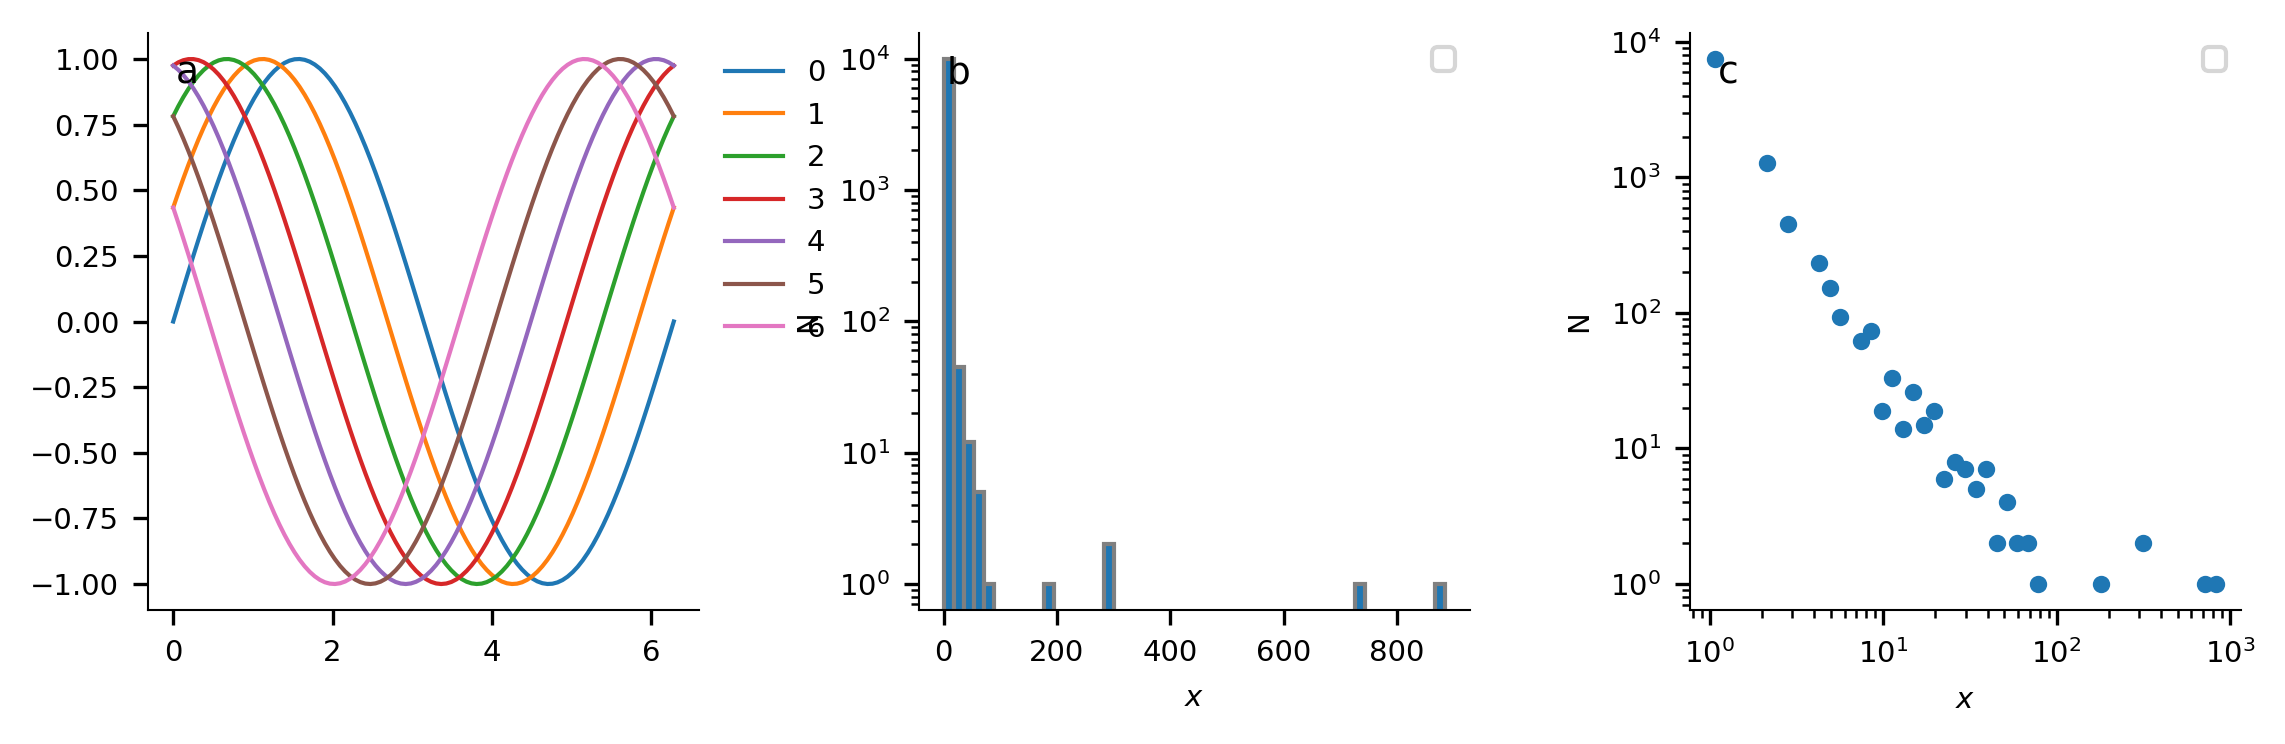

In [1]:
import polars as pl
import matplotlib.pyplot as plt
from constant import openalex_path
import numpy as np

import scienceplots
plt.rcParams['figure.dpi'] = 300
plt.style.use(['nature']) # start with ['science'] then ['nature']. use 'notebook', 'no-latex', 'cjk-jp-font' if needed.
plt.rcParams.update({'font.size': 12})
# https://github.com/garrettj403/SciencePlots
print(plt.rcParams['axes.prop_cycle'].by_key()['color'])


fig, (ax1, ax2, ax3) = plt.subplots(1,3, figsize=(9,2.5))
fig.subplots_adjust(hspace=0.1, wspace=0.4)

n = 7
x = np.linspace(0, 2*np.pi, 100)
for i in range(n):
    ax1.plot(x, np.sin(x+np.pi/n*i), label=i)
ax1.spines[['right', 'top']].set_visible(False)
ax1.tick_params(which='both', top=False, right=False)
ax1.legend(loc='upper left', bbox_to_anchor=(1,1),frameon=False)
ax1.text(0.05, 0.96, 'a', va='top', transform=ax1.transAxes, fontsize=9)


np.random.seed(0)
a = 2.5  # べき分布の指数（べき指数）
size = 10000  # データのサイズ
data = np.random.zipf(a, size)

ax2.hist(data, bins=50, log=True, edgecolor='gray')
ax2.set_xlabel('$x$')
ax2.set_ylabel('N')
ax2.spines[['right', 'top']].set_visible(False)
ax2.tick_params(which='both', top=False, right=False)
ax2.legend()
ax2.text(0.05, 0.96, 'b', va='top', transform=ax2.transAxes, fontsize=9)

bins = np.logspace(np.log10(data.min()), np.log10(data.max()), 50)
hist, bin_edges = np.histogram(data, bins=bins)
bin_centers = (bin_edges[:-1] + bin_edges[1:]) / 2
ax3.scatter(bin_centers, hist, s=10)
ax3.set_xscale('log')  # x軸を対数スケールに設定
ax3.set_yscale('log')  # y軸を対数スケールに設定
ax3.set_xlabel('$x$')
ax3.set_ylabel('N')
ax3.spines[['right', 'top']].set_visible(False)
ax3.tick_params(which='both', top=False, right=False)
ax3.legend()
ax3.text(0.05, 0.96, 'c', va='top', transform=ax3.transAxes, fontsize=9)

In [2]:
two_year_window = True
# CNS_papers_details_df =  pl.read_parquet("./data/CNS_paper_details.parquet")
CNS_papers_details_df =  pl.read_parquet("./data/CNS_papers_inferred_subjects_Life.parquet")
CNS_citing_preprints_df = pl.read_parquet("./data/citing_preprints_full_enhanced.parquet").filter(pl.col("work_id").is_in(CNS_papers_details_df["work_id"].to_list()))
if two_year_window==True:
    CNS_citing_preprints_df = (
        CNS_citing_preprints_df
        .filter(pl.col("publication_year") - pl.col("publication_year_preprint") < 3)
    )
journal_detail = pl.read_parquet("./data/CNS_journal_inception.parquet")
preprint = pl.read_parquet("./data/preprints_opal_0129_curation_imputed.parquet").drop_nulls("work_id")

In [3]:
CNS_papers_details_df.select("publication_year").max()

publication_year
i64
2023


In [4]:
threshold = 5

In [5]:
source_lf = pl.scan_parquet(f"{openalex_path}/works/primary_location_id/*")

sources_journal = (
    pl.scan_parquet("./data/CNS_citing_journals.parquet").select("referenced_works")
    .join(source_lf, left_on="referenced_works", right_on="work_id", how="left")
    .group_by("primary_location_id").len()
    .filter(pl.col("len") >= threshold)
    .drop("len")
)

all_works_count = (
    pl.scan_parquet(f"{openalex_path}/works/publication_year/*")
    .join(source_lf, on="work_id", how="left")
    .join(sources_journal, left_on="primary_location_id", right_on="primary_location_id", how="semi")
    .filter(pl.col("publication_year").is_between(2000, 2024))
    .group_by("publication_year")
    .agg(
        pl.count("work_id").alias("total_works")
    )
    .collect(engine="streaming")
)
all_works_count.sort("publication_year")

publication_year,total_works
i64,u32
2000,1537247
2001,1556598
2002,1643611
2003,1789889
2004,1895811
…,…
2020,5062335
2021,4836914
2022,4993575


In [6]:
sources_preprint = (
    CNS_citing_preprints_df
    .select(pl.col("primary_category").alias("primary_location_id"))
    .group_by("primary_location_id").len()
    .filter(pl.col("len") >= threshold)
    .drop("len")
)

# ratio of preprint counts by year bins
preprint_count = (
    preprint
    .join(sources_preprint, left_on="primary_category", right_on="primary_location_id", how="semi")
    .group_by("publication_year_preprint")
    .agg(
        pl.count("work_id").alias("num_preprints"),
        pl.col("curated_doi").is_null().sum().alias("num_noncurated_preprints"),
        pl.col("curated_doi").is_not_null().sum().alias("num_curated_preprints")
    )
    .filter(pl.col("publication_year_preprint").is_between(2000, 2024))
    .sort("publication_year_preprint")
)
preprint_count

publication_year_preprint,num_preprints,num_noncurated_preprints,num_curated_preprints
i32,u32,u32,u32
2000,8566,2500,6066
2001,9555,2259,7296
2002,10127,2260,7867
2003,11518,2480,9038
2004,12528,2409,10119
…,…,…,…
2020,117077,45406,71671
2021,117932,48179,69753
2022,119165,52859,66306


In [7]:
all_works_count.sort("publication_year")

publication_year,total_works
i64,u32
2000,1537247
2001,1556598
2002,1643611
2003,1789889
2004,1895811
…,…
2020,5062335
2021,4836914
2022,4993575


In [8]:
noncurated = pl.when(pl.col("curated_doi").is_null()).then(pl.col("work_id"))
curated = pl.when(pl.col("curated_doi").is_not_null()).then(pl.col("work_id"))

pub_year_preprint_citation_count = (
    CNS_citing_preprints_df
    .join(journal_detail, on="primary_location_id", how="inner")
    .filter(pl.col("inception_period") == "Before 2000")
    .group_by("publication_year")
    .agg(
        pl.n_unique("work_id").alias("num_citing_preprints"),
        pl.count("work_id").alias("num_citation_preprints"),
        noncurated.n_unique().alias("num_citing_noncurated_preprints"),
        noncurated.count().alias("num_citation_noncurated_preprints"),
        curated.n_unique().alias("num_citing_curated_preprints"),
        curated.count().alias("num_citation_curated_preprints"),
    )
    .sort("publication_year")
)

CNS_paper_yearly_count = (
    CNS_papers_details_df
    .join(journal_detail, on="primary_location_id", how="inner")
    .filter(pl.col("inception_period") == "Before 2000")
    .group_by("publication_year")
    .agg(
        pl.count().alias("total_article"),
        pl.col("ref_count").sum().alias("total_ref_count")
    )
)

article_count = (
    preprint_count
    .join(all_works_count, left_on="publication_year_preprint", right_on="publication_year", how="left")
    .with_columns(
        (pl.col("num_preprints") / pl.col("total_works")).alias("preprint_ratio"),
        (pl.col("num_noncurated_preprints") / pl.col("total_works")).alias("preprint_ratio_noncurated"),
        (pl.col("num_curated_preprints") / pl.col("total_works")).alias("preprint_ratio_curated")
    )
)
article_count

/tmp/ipykernel_3553562/3296052499.py:26: DeprecationWarning: `pl.count()` is deprecated. Please use `pl.len()` instead.
(Deprecated in version 0.20.5)
  pl.count().alias("total_article"),


publication_year_preprint,num_preprints,num_noncurated_preprints,num_curated_preprints,total_works,preprint_ratio,preprint_ratio_noncurated,preprint_ratio_curated
i32,u32,u32,u32,u32,f64,f64,f64
2000,8566,2500,6066,1537247,0.005572,0.001626,0.003946
2001,9555,2259,7296,1556598,0.006138,0.001451,0.004687
2002,10127,2260,7867,1643611,0.006161,0.001375,0.004786
2003,11518,2480,9038,1789889,0.006435,0.001386,0.005049
2004,12528,2409,10119,1895811,0.006608,0.001271,0.005338
…,…,…,…,…,…,…,…
2020,117077,45406,71671,5062335,0.023127,0.008969,0.014158
2021,117932,48179,69753,4836914,0.024382,0.009961,0.014421
2022,119165,52859,66306,4993575,0.023864,0.010585,0.013278


In [9]:
citing_preprint_probability = (
    pub_year_preprint_citation_count
    .join(preprint_count, left_on="publication_year", right_on="publication_year_preprint", how="left")
    .join(CNS_paper_yearly_count, on="publication_year", how="inner")
    .join(all_works_count, on="publication_year", how="left")
    .filter(pl.col("publication_year").is_between(2000,2024))
    .with_columns(
        (pl.col("num_citing_noncurated_preprints") / pl.col("total_article")).alias("citing_noncurated_preprint_probability"),
        (pl.col("num_citing_curated_preprints") / pl.col("total_article")).alias("citing_curated_preprint_probability"),
        (pl.col("num_citation_noncurated_preprints") / pl.col("total_ref_count")).alias("citation_noncurated_preprint_probability"),
        (pl.col("num_citation_curated_preprints") / pl.col("total_ref_count")).alias("citation_curated_preprint_probability"),
        (pl.col("num_noncurated_preprints") / pl.col("total_works")).alias("noncurated_preprint_ratio"),
        (pl.col("num_curated_preprints") / pl.col("total_works")).alias("curated_preprint_ratio")
    )
    .sort("publication_year")
)

In [10]:
article_count.filter(pl.col("publication_year_preprint").is_between(2008, 2011))

publication_year_preprint,num_preprints,num_noncurated_preprints,num_curated_preprints,total_works,preprint_ratio,preprint_ratio_noncurated,preprint_ratio_curated
i32,u32,u32,u32,u32,f64,f64,f64
2008,16308,2682,13626,2393537,0.006813,0.001121,0.005693
2009,7467,1915,5552,2567909,0.002908,0.000746,0.002162
2010,8538,2280,6258,2679770,0.003186,0.000851,0.002335
2011,9737,2464,7273,3078774,0.003163,0.0008,0.002362


In [11]:
citing_preprint_probability.select(
    "publication_year", 
    "total_ref_count", 
    "num_citation_noncurated_preprints", 
    "citation_noncurated_preprint_probability"
    )

publication_year,total_ref_count,num_citation_noncurated_preprints,citation_noncurated_preprint_probability
i64,u32,u32,f64
2003,76473,1,0.000013
2004,125044,0,0.0
2005,142126,1,0.000007
2006,138179,3,0.000022
2007,134788,1,0.000007
…,…,…,…
2019,211019,305,0.001445
2020,234788,742,0.00316
2021,223413,873,0.003908


In [12]:
1020 / 218897

0.004659725807114762

/tmp/ipykernel_3553562/4040948488.py:6: RuntimeWarning: divide by zero encountered in log10
  np.log10((pdf["citation_curated_preprint_probability"] / pdf["curated_preprint_ratio"]).to_list()),
/tmp/ipykernel_3553562/4040948488.py:11: RuntimeWarning: divide by zero encountered in log10
  np.log10((pdf["citation_noncurated_preprint_probability"] / pdf["noncurated_preprint_ratio"]).to_list()),


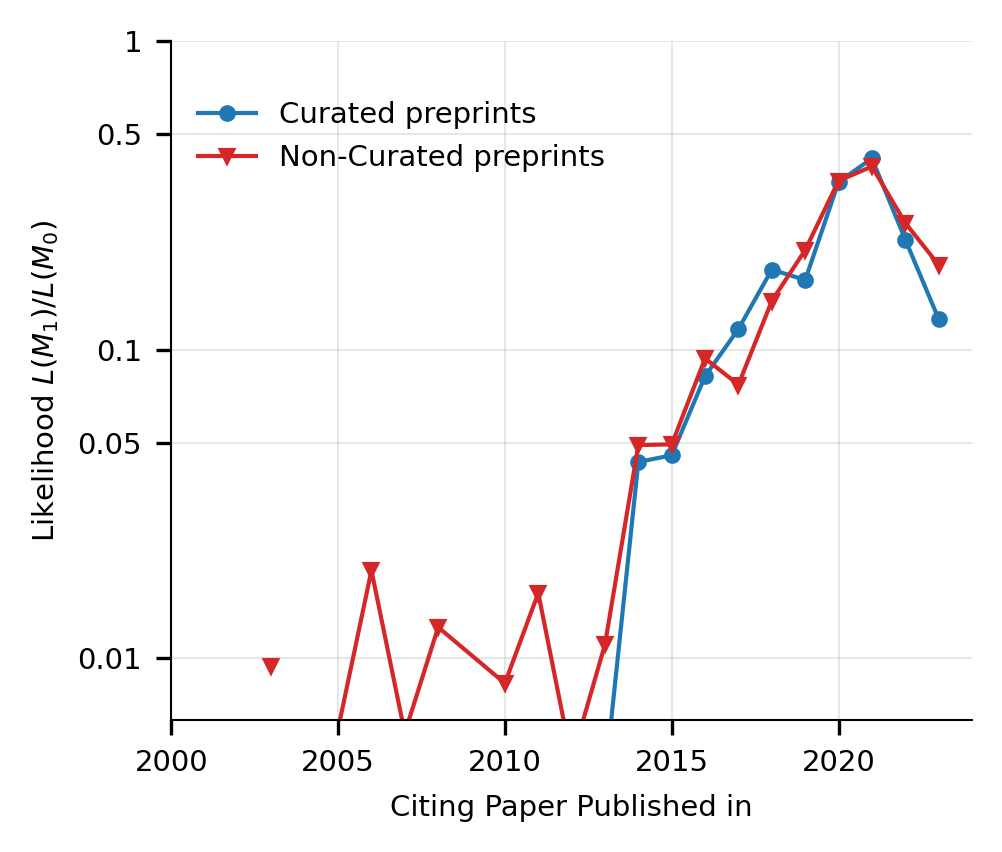

In [13]:
pdf = citing_preprint_probability

plt.figure(figsize=(3.5, 3))
plt.plot(
    pdf["publication_year"].to_list(),
    np.log10((pdf["citation_curated_preprint_probability"] / pdf["curated_preprint_ratio"]).to_list()),
    marker="o", markersize=3, linestyle="-", color="tab:blue", label="Curated preprints"
)
plt.plot(
    pdf["publication_year"].to_list(), 
    np.log10((pdf["citation_noncurated_preprint_probability"] / pdf["noncurated_preprint_ratio"]).to_list()), 
    marker="v", markersize=3, linestyle="-", color="tab:red", label="Non-Curated preprints"
)

plt.xticks(range(2000, 2025, 5))

plt.xlabel("Citing Paper Published in")
plt.ylabel("Likelihood $L(M_1) / L(M_0)$")

import numpy as np

# 1, 0.5, 0.1, 0.05, 0.01, 0.005, 0.001 の刻み（縦軸は log10 をとった値）
tick_values = [m * 10.0**(-k) for k in range(0, 4) for m in (1, 0.5)][:-1]
plt.yticks(np.log10(tick_values), [f"{v:g}" for v in tick_values])

plt.grid(alpha=0.3)
plt.xlim(2000,2024)
plt.ylim(-2.2,0)
# plt.ylim(-3,0)
plt.legend(frameon=False, loc="upper left", bbox_to_anchor=(0, 0.95))

# top and right spines are removed
plt.gca().spines['top'].set_visible(False)
plt.gca().spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig("./figures/citing_preprint_probability.pdf")

In [14]:
citing_preprint_probability.filter(pl.col("publication_year").is_between(2008, 2013)).select("publication_year", "num_citing_curated_preprints")

publication_year,num_citing_curated_preprints
i64,u32
2008,1
2010,1
2011,2
2012,2
2013,3
